<a href="https://colab.research.google.com/github/WesleyS-GH/DATA201-labs/blob/main/Assignments/Week8_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [70]:
%pip -q install ISLP

In [71]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

**Part 1**

In [72]:
hitters = load_data('Hitters')
print('Original shape:', hitters.shape)
display(hitters.head())
print('Missing values:')
print(hitters.isna().sum().sort_values())

Original shape: (322, 20)


,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,293,66,1,30,29,14,1,293,66,1,30,29,14,A,E,446,33,20,NaN,A
1,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
2,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
3,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
4,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N


Missing values:
AtBat         0
Hits          0
HmRun         0
Runs          0
RBI           0
Walks         0
Years         0
CAtBat        0
CHits         0
CHmRun        0
CRuns         0
CRBI          0
CWalks        0
League        0
Division      0
PutOuts       0
Assists       0
Errors        0
NewLeague     0
Salary       59
dtype: int64


In [73]:
hitters = hitters.dropna(subset=['Salary']).copy()
X = hitters.drop(columns='Salary')
y = hitters['Salary']
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
category_cols = X.select_dtypes(exclude=np.number).columns.tolist()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

In [74]:
def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numeric_cols),
            ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), category_cols)
            ])
def measure(name, fitted_model):
    train_pred = fitted_model.predict(X_train)
    test_pred = fitted_model.predict(X_test)
    return {
        'Model': name,
        'Train RMSE': np.sqrt(mean_squared_error(y_train, train_pred)),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, test_pred)),
        'Test R²': r2_score(y_test, test_pred)
    }
    results = []

In [75]:
alpha_examples = [0.1, 10, 100]
rows = []
for kind, estimator in [('Lasso', Lasso(max_iter=30000))]:
    for a in alpha_examples:
        pipe = Pipeline([
            ('preprocess', make_preprocessor()),
            ('model', estimator.set_params(alpha=a))
        ])
        pipe.fit(X_train, y_train)


        coefs = pipe.named_steps['model'].coef_


        rows.append({
            'Model': kind, 'alpha': a,
            'Nonzero coefficients': int(np.sum(np.abs(coefs) > 1e-6)),
            'Training RMSE': np.sqrt(mean_squared_error(y_train, pipe.predict(X_train))),
            'Testing RMSE': np.sqrt(mean_squared_error(y_test, pipe.predict(X_test)))
        })
alpha_table = pd.DataFrame(rows)
display(alpha_table.round(2))

,Model,alpha,Nonzero coefficients,Training RMSE,Testing RMSE
0,Lasso,0.1,19,289.38,356.83
1,Lasso,10.0,9,303.10,381.84
2,Lasso,100.0,5,341.39,395.12


1. As α increases, what happens to the number of retained predictors?

As α increases the number of retained predictors decreases, the lowest alpha of 0.1 had 19 retained predictors while an alpha of 10 or 100 had 9 and 5 retained predictors respectively.


2. Does a smaller number of predictors always lead to a lower test RMSE?

No, and this case shows that, as when the alpha increased, which lead to a smaller number of predictors kept the test RMSE did not get lower, rather the test RMSE increased.

**Part 2**

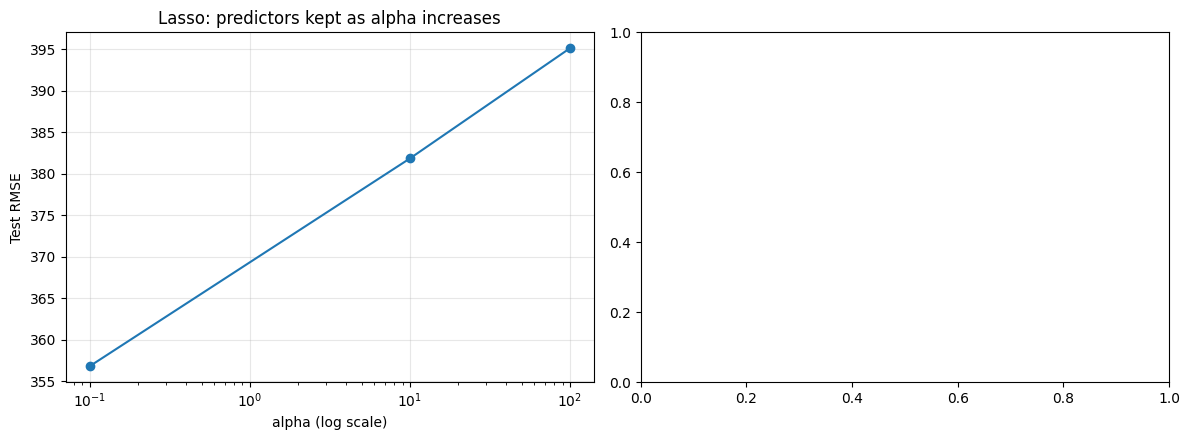

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, kind in zip(axes, ['Lasso']):
    subset = alpha_table[alpha_table['Model'] == kind]
    ax.semilogx(subset['alpha'], subset['Testing RMSE'], marker='o')
    ax.set_title(f'{kind}: predictors kept as alpha increases')
    ax.set_xlabel('alpha (log scale)')
    ax.set_ylabel('Test RMSE')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

1. Which α produces the lowest test RMSE among the three values?

An α of 0.1 produced to lowest test RMSE among the three values, being the only value below 360 while the two toher alpha values had an RMSE greater than 380.


2. Which α appears to cause the most underfitting? Explain using bias.

An α of 100 seems to cause the most underfitting as it has both a poor training and testing RMSE value. This is because an alpha of 100 leads to the smallest amount of predictors retained out of the three alpha values, which makes the model much simpler leading to bias due to the simplicity of the model.


3. Why might a model with higher training RMSE produce lower test RMSE?

A model with a higher training RMSE may produce a lower test RMSE because it is overfitting. If the model learns the training data too well it's variance decreases and performs worse on new unseen data. This is also because when a model begins overfitting it starts trying to predict noise which lowers it's performance on testing data.

**Part 3**

In [77]:
feature_names = pipe.named_steps['preprocess'].get_feature_names_out()

coef_table = pd.DataFrame({
    'Feature': feature_names,
    'OLS': pipe.named_steps['model'].coef_
})

display(coef_table.round(2))

,Feature,OLS
0,num__AtBat,0.00
1,num__Hits,76.59
2,num__HmRun,0.00
3,num__Runs,0.00
4,num__RBI,0.00
5,num__Walks,16.17
6,num__Years,0.00
7,num__CAtBat,0.00
8,num__CHits,0.00
9,num__CHmRun,0.00


1. Identify two predictors that Lasso sets to zero at α = 100.

Lasso set the predictors num__Assists and Num__CWalks to zero at an alpha of 100.


2. Does setting their coefficients to zero prove that these predictors have no relationship
with salary? Explain.

No, Lasso setting predictors coefficients to zero does not prove that these predictors have no relationship with salary, it could also mean the predictor is correlated with another predictor which leads to it becoming zero.


3. If two models have very similar test RMSE but one uses fewer predictors, which would
you prefer? Explain your answer in terms of interpretability and predictive performance.

Out of the two models with a similar test RMSE the one with few predictors would be the one I would prefer as it is much simpler. The model with fewer predictors is easier to use later on as it has less predictors it has to use in its calculations, it also is far easier to interpret as there are less variables present so people reading the results only have to focus on the select variables present.

**Part 4**

-  Scenario A: A researcher has data from 80 patients with 200 medical measurements. The
goal is to identify a small number of measurements that may be useful for predicting
disease severity.

Lasso, as they want to identify as small number of measurements and lasso can be used to cut down the number of predictors to their desired amount. CV may also be useful here to ensure the actual best small number of measurements are selected.


- Scenario B: A company wants to predict employee salaries using 40 predictors. Many
predictors are strongly correlated, and the company believes most contain useful
information. Keeping all predictors is not a concern.

Lasso and ridge, as it was mentioned how keeping all predictors isn't a concern, and many predictors are strongly correlated so regulating those variables would be good as linear regression struggles when predictors are correlated. Lasso may be sightly better as getting rid of some of the strongly correlated predictors may be useful and keeping all predictors wasn't a concern highlighted.


- Scenario C: A researcher has 10,000 observations and only three predictors. The
relationship appears approximately linear, and the researcher wants a simple model that is
easy to interpret.

Ordinary linear regression should work just fine here as it is stated that the relationship appears linear, they want a simple model, and there are only three predictors to regulation may not do many or may do too much.


- Scenario D: A company has 500 observations and 25 predictors. It is unclear how many
predictors are useful or how strongly they are correlated. The company wants the most
accurate predictions possible.

Either ridge or lasso could be effective options here as they can be used to see if any predictors or useful, and lasso specifically can be used to see if any predictors may be correlated. But just from this information it is unclear which is the best method for this scenario.